# Gaussian process operator in a minute

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/csccm-iitd/GPO/blob/main/notebooks/quickstart.ipynb)

A GPO places a Gaussian process prior over the solution operator of a PDE,

$$f \sim \mathcal{GP}(0, k), \qquad k\big((a, x), (a', x')\big) = \phi(a, x)^\top \Lambda\, \phi(a', x') + s^2\, k_a\big(\psi(a), \psi(a')\big)\, k_x(x, x'),$$

where $\phi$ and $\psi$ are features of a neural operator. Inference is exact, and posterior **function draws** come from
Matheron's rule, $f \mid y = f + k(\cdot, X) K^{-1}(y - f(X) - \varepsilon)$. This notebook trains a small operator on
a synthetic problem, fits a GPO on top, and uses its joint draws for sensor fusion and for the uncertainty of a
derived quantity.

In [1]:
try:
    import gpo
except ImportError:
    %pip install -q git+https://github.com/csccm-iitd/GPO
import math, torch, matplotlib.pyplot as plt
from gpo import GPO, SensorUpdate, greedy_sensors
from gpo.operators import FNO
dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)

## A nonlinear operator

Inputs are Gaussian random fields $a$ on the periodic interval; the output is $u = e^{t\Delta}\,\sin(3a)$ with
$t = 2\times 10^{-3}$, a pointwise nonlinearity followed by diffusion.

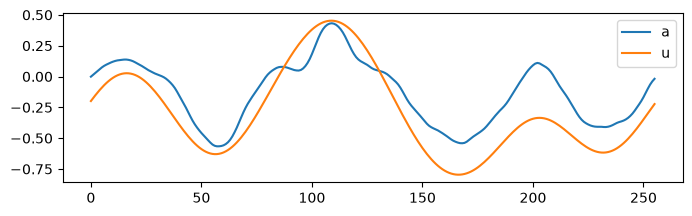

In [2]:
n, s = 700, 256
k = torch.fft.rfftfreq(s, 1 / s)
def grf(n):
    coef = torch.randn(n, len(k), dtype=torch.cfloat) * (1 + (k / 4) ** 2) ** -1.5
    return torch.fft.irfft(coef, n=s) * s / 6
def solve(a):
    return torch.fft.irfft(torch.fft.rfft(torch.sin(3 * a)) * torch.exp(-(2 * math.pi * k) ** 2 * 2e-3), n=s)
a = grf(n); u = solve(a)
x = a[..., None].to(dev); y = u.to(dev)
tr, va, te = slice(0, 300), slice(300, 500), slice(500, 700)
xm, xs, ym, ys = x[tr].mean(), x[tr].std(), y[tr].mean(), y[tr].std()
X, Y = (x - xm) / xs, ((y - ym) / ys).double()
plt.figure(figsize=(8, 2.2)); plt.plot(a[0], label="a"); plt.plot(u[0], label="u"); plt.legend(); plt.show()

## Train the operator that supplies the kernel features

In [3]:
op = FNO([16], width=32, layers=4).to(dev)
opt = torch.optim.AdamW(op.parameters(), 2e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=300 * 6)
rel = lambda p, t: ((p - t).norm(dim=-1) / t.norm(dim=-1)).mean()
for epoch in range(300):
    for idx in torch.randperm(300, device=dev).split(50):
        loss = rel(op(X[idx]).squeeze(-1), Y[idx].float())
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
with torch.no_grad():
    print(f"operator test error {100 * rel(op(X[te]).squeeze(-1), Y[te].float()).item():.3f}%")

operator test error 0.844%


## Fit the GPO

Kernel hyperparameters are learned on the exact marginal likelihood of random subsets of training fields, then
re-estimated on the evidence of held-out fields, $-\log p(y_\text{val} \mid y_\text{train})$, so that the
uncertainty reflects generalisation error rather than training error.

In [4]:
model = GPO(op, (s,)).to(dev)
model.op.requires_grad_(False)
opt = torch.optim.Adam([p for n_, p in model.named_parameters() if not n_.startswith("op.")], 1e-2)
for step in range(200):
    i = torch.randperm(300, device=dev)[:256]
    loss = model.nll(X[tr][i], Y[tr][i]); opt.zero_grad(); loss.backward(); opt.step()
hyp = [p for n_, p in model.named_parameters() if n_.startswith("log_")]
model.requires_grad_(False); [p.requires_grad_(True) for p in hyp]
opt = torch.optim.Adam(hyp, 1e-2)
for step in range(200):
    ic, ih = torch.randperm(300, device=dev)[:250], torch.randperm(200, device=dev)[:100]
    loss = model.conditional_nll(X[tr][ic], Y[tr][ic], X[va][ih], Y[va][ih]); opt.zero_grad(); loss.backward(); opt.step()
model.requires_grad_(False)
model.eval().fit(X[tr], Y[tr])
mu, var = model.predict(X[te])
sd = (var + model.noise()).sqrt()
inside = ((Y[te] - mu).abs() <= 1.96 * sd).float().mean()
print(f"GPO test error {100 * rel(mu, Y[te]).item():.3f}%   95% interval coverage {inside.item():.3f}")

GPO test error 0.844%   95% interval coverage 0.924


## Matheron's rule: from prior draws to posterior draws

Each prior function draw is moved onto the data by the correction term. The draws are joint over the whole field,
so they are physically meaningful functions rather than independent per-point noise.

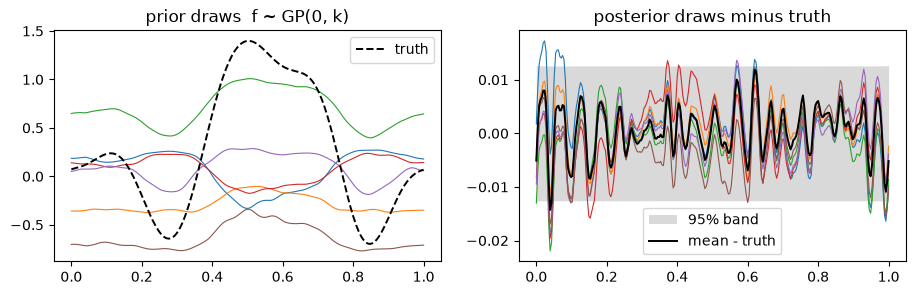

In [5]:
i = 0
post, prior = model.sample(X[te][i:i + 1], n_samples=6, return_prior=True)
grid = torch.linspace(0, 1, s)
band = 1.96 * sd[i].cpu()
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for j in range(6):
    ax[0].plot(grid, prior[j, 0].cpu(), lw=0.8)
    ax[1].plot(grid, (post[j, 0] - Y[te][i]).cpu(), lw=0.8)
ax[0].plot(grid, Y[te][i].cpu(), "k--", lw=1.4, label="truth"); ax[0].legend()
ax[1].fill_between(grid, -band, band, color="0.85", lw=0, label="95% band")
ax[1].plot(grid, (mu[i] - Y[te][i]).cpu(), "k", lw=1.4, label="mean - truth"); ax[1].legend()
ax[0].set_title("prior draws  f ~ GP(0, k)"); ax[1].set_title("posterior draws minus truth")
plt.show()

## Sensor fusion at test time

A few noisy readings of the unknown output are absorbed exactly, with no retraining. Sensors are placed one at a
time where the posterior variance is largest.

 0 sensors: mean error 0.804%
 2 sensors: mean error 0.757%
 4 sensors: mean error 0.699%
 8 sensors: mean error 0.658%
16 sensors: mean error 0.641%


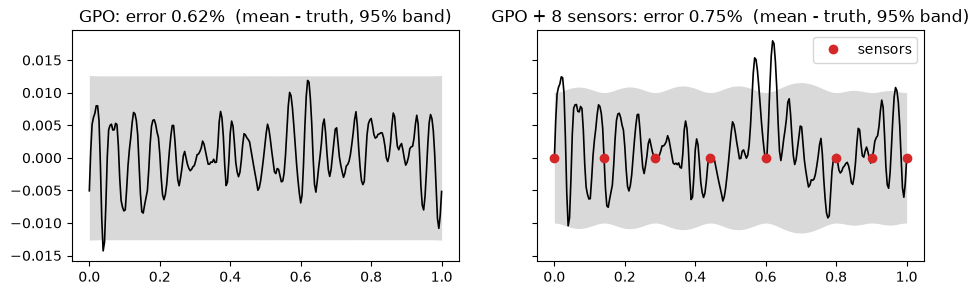

In [6]:
errs = {m: [] for m in (0, 2, 4, 8, 16)}
for i in range(50):
    x1, y1 = X[te][i:i + 1], Y[te][i]
    J, _ = greedy_sensors(model, x1, 16, var=var[i], r=1e-6)
    for m in errs:
        m1 = mu[i] if m == 0 else SensorUpdate(model, x1, J[:m], r=1e-6).mean(mu[i], y1[J[:m]])
        errs[m].append(((m1 - y1).norm() / y1.norm()).item())
for m, e in errs.items():
    print(f"{m:2d} sensors: mean error {100 * sum(e) / len(e):.3f}%")
i = 0; x1, y1 = X[te][i:i + 1], Y[te][i]
J, _ = greedy_sensors(model, x1, 8, var=var[i], r=1e-6)
upd = SensorUpdate(model, x1, J, r=1e-6)
m1, v1 = upd.mean(mu[i], y1[J]), upd.variance(var[i])
fig, ax = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for a_, m_, v_, t_ in [(ax[0], mu[i], var[i], "GPO"), (ax[1], m1, v1, "GPO + 8 sensors")]:
    b_ = 1.96 * (v_ + model.noise()).sqrt().cpu()
    a_.fill_between(grid, -b_, b_, color="0.85", lw=0); a_.plot(grid, (m_ - y1).cpu(), "k", lw=1.2)
    a_.set_title(f"{t_}: error {100 * ((m_ - y1).norm() / y1.norm()).item():.2f}%  (mean - truth, 95% band)")
ax[1].plot(grid[J.cpu()], 0 * grid[J.cpu()], "o", color="C3", label="sensors"); ax[1].legend(); plt.show()

## Uncertainty of a derived quantity

The maximum of the field is a nonlinear functional; its distribution comes directly from the joint draws.

In [7]:
draws = model.sample(X[te], n_samples=256)
q = draws.amax(-1); lo, hi = q.quantile(0.05, 0), q.quantile(0.95, 0); t = Y[te].amax(-1)
print(f"90% intervals for max u contain the truth for {((t >= lo) & (t <= hi)).float().mean().item():.0%} of test inputs")

90% intervals for max u contain the truth for 75% of test inputs
